In [1]:
import zipfile
import urllib.request
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

urllib.request.urlretrieve(url, "student_performance.zip")

os.makedirs("student_data", exist_ok=True)

with zipfile.ZipFile("student_performance.zip", "r") as z:
    z.extractall("student_data")

inner_zip_path = "student_data/student.zip"

if os.path.exists(inner_zip_path):
    with zipfile.ZipFile(inner_zip_path, "r") as z:
        z.extractall("student_data")

df = pd.read_csv("student_data/student-mat.csv", sep=";")

print("Dataset Loaded Successfully")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully
Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print("Dataset Information")
df.info()

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Records")
print(df.duplicated().sum())

print("\nStatistical Summary")
display(df.describe(include="all"))

df = df.drop_duplicates().copy()

print("\nCleaned Dataset Shape:", df.shape)

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    ob

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395,395,395.000000,395,395,395,395.000000,395.000000,395,395,...,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,349,208,NaN,307,281,354,NaN,NaN,141,217,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.696203,NaN,NaN,NaN,2.749367,2.521519,NaN,NaN,...,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,NaN,NaN,1.276043,NaN,NaN,NaN,1.094735,1.088201,NaN,NaN,...,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,3.000000,2.000000,NaN,NaN,...,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000



Cleaned Dataset Shape: (395, 33)


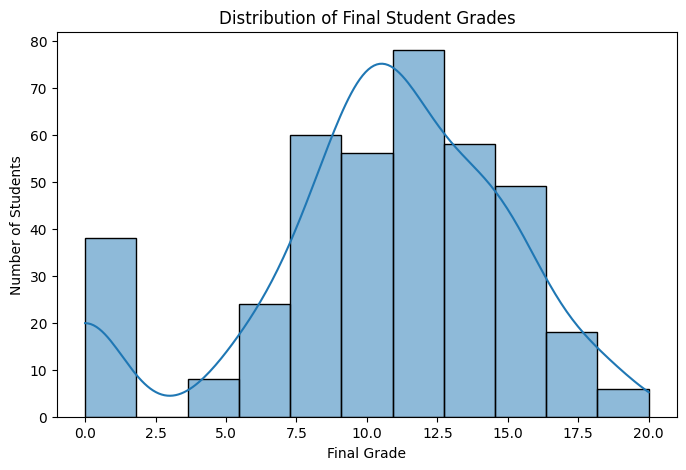

In [3]:
plt.figure(figsize=(8,5))

sns.histplot(df["G3"], bins=11, kde=True)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

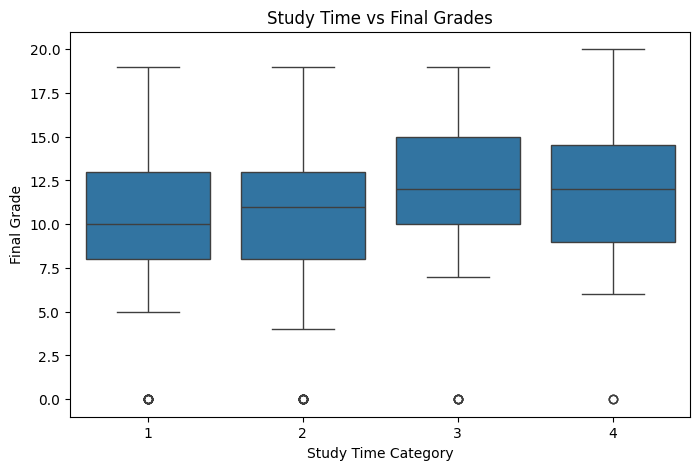

In [4]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grades")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade")

plt.show()

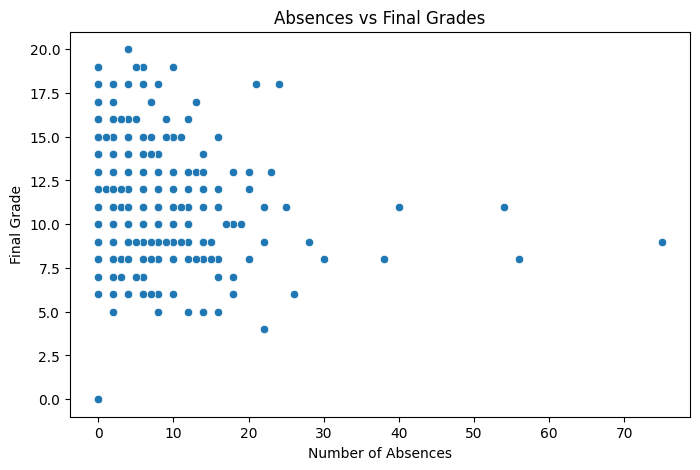

In [5]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()

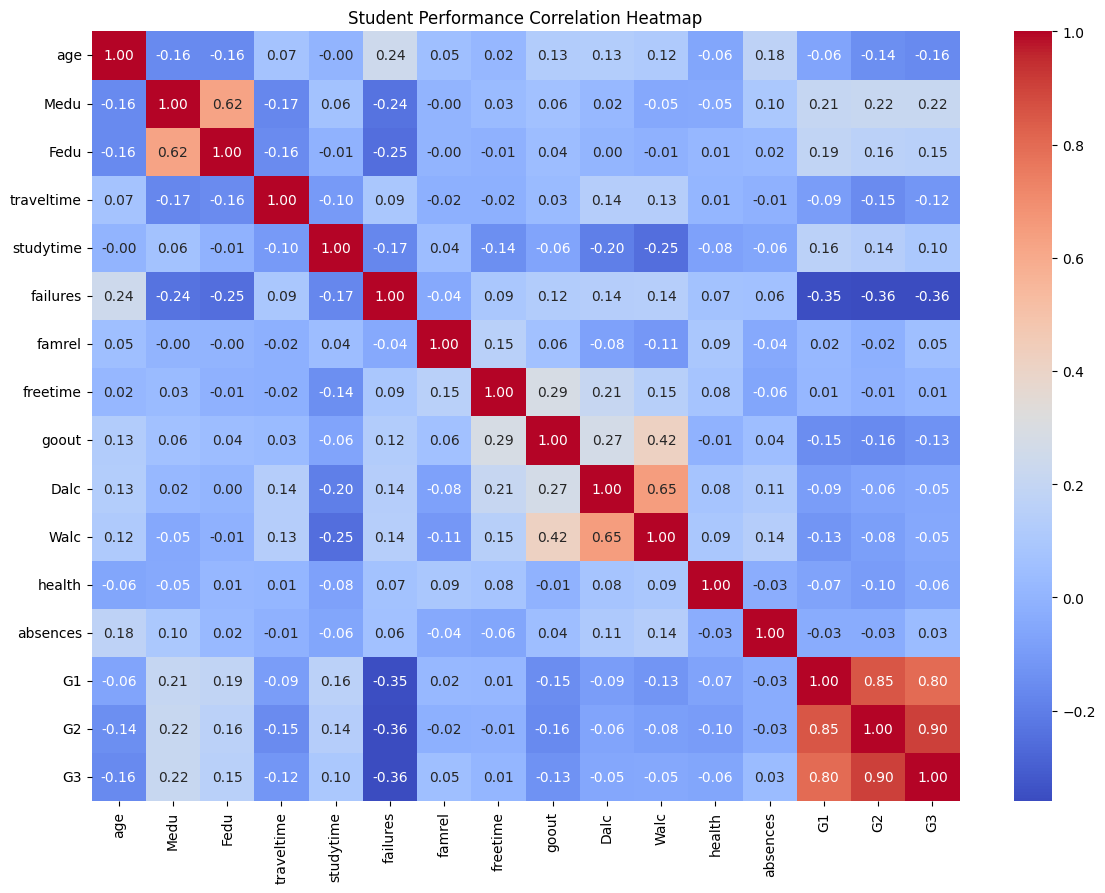

In [6]:
plt.figure(figsize=(14,10))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Student Performance Correlation Heatmap")

plt.show()

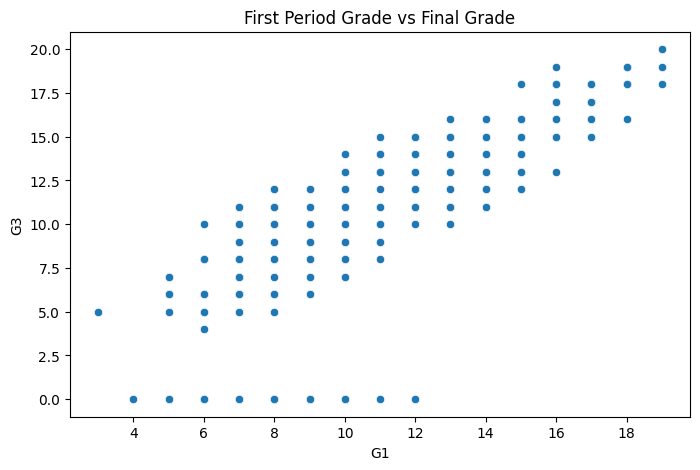

In [7]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x="G1", y="G3")

plt.title("First Period Grade vs Final Grade")
plt.xlabel("G1")
plt.ylabel("G3")

plt.show()

In [8]:
X = df.drop(columns=["G1", "G2", "G3"])

y = df["G3"]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:", "G3")

Input Features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Target Variable: G3


In [9]:
categorical_features = X.select_dtypes(include="object").columns.tolist()

numerical_features = X.select_dtypes(exclude="object").columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 316
Testing Samples: 79


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, random_state=42)
}

print("Models Created Successfully")

Models Created Successfully


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline
    predictions[name] = y_pred

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,3.009494,14.147578,3.761327,0.310044
3,Gradient Boosting,3.072576,15.300082,3.911532,0.253838
0,Linear Regression,3.395261,17.603737,4.195681,0.141492
1,Decision Tree,3.569620,22.810127,4.775995,-0.112415


In [18]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = predictions[best_model_name]

print("Best Model:", best_model_name)

print("Best RMSE:", results_df.iloc[0]["RMSE"])

print("Best R2 Score:", results_df.iloc[0]["R2 Score"])

Best Model: Random Forest
Best RMSE: 3.761326691609313
Best R2 Score: 0.31004409323914617


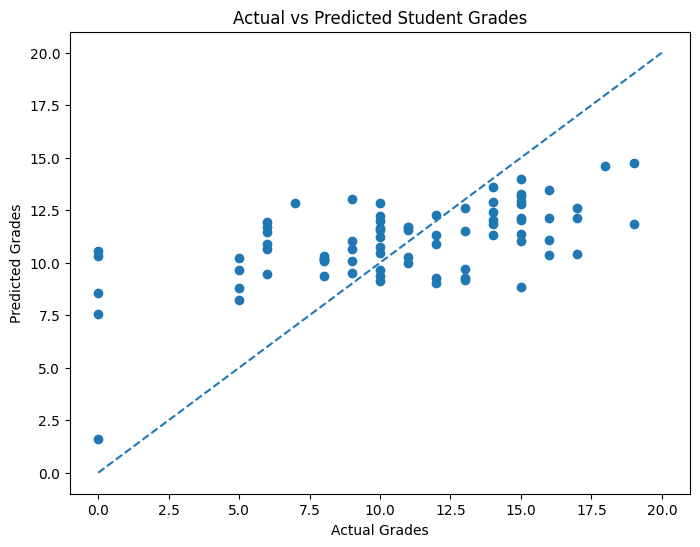

In [19]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, best_predictions)

plt.plot(
    [0,20],
    [0,20],
    linestyle="--"
)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")

plt.title("Actual vs Predicted Student Grades")

plt.show()

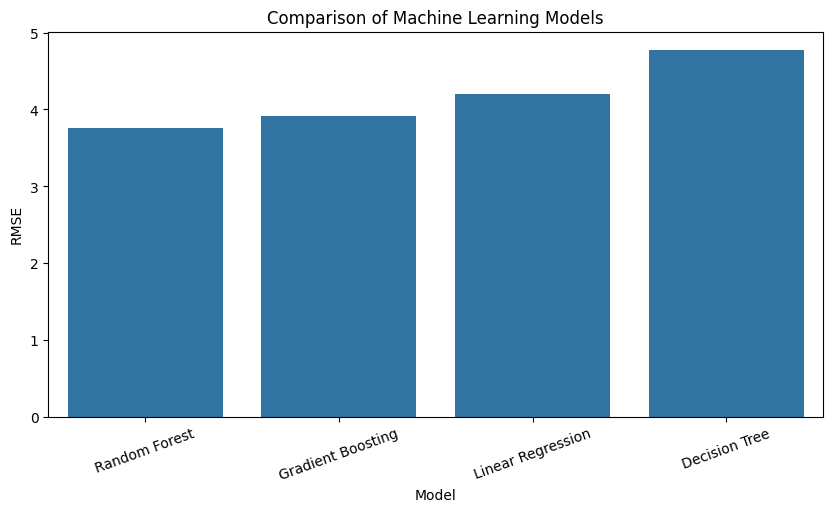

In [20]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("RMSE")
plt.xticks(rotation=20)

plt.show()

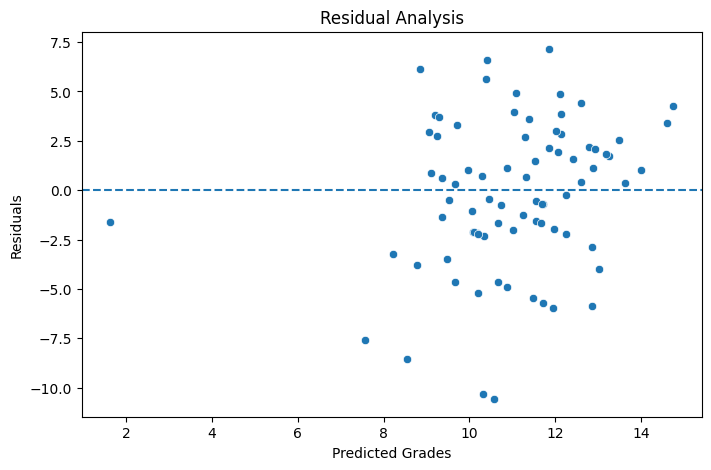

In [21]:
residuals = y_test - best_predictions

plt.figure(figsize=(8,5))

sns.scatterplot(
    x=best_predictions,
    y=residuals
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Grades")
plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.show()

,Feature,Importance
12,num__absences,0.187819
5,num__failures,0.145973
11,num__health,0.049319
8,num__goout,0.046231
0,num__age,0.037095
4,num__studytime,0.032123
7,num__freetime,0.028957
3,num__traveltime,0.027700
2,num__Fedu,0.026850
10,num__Walc,0.025742


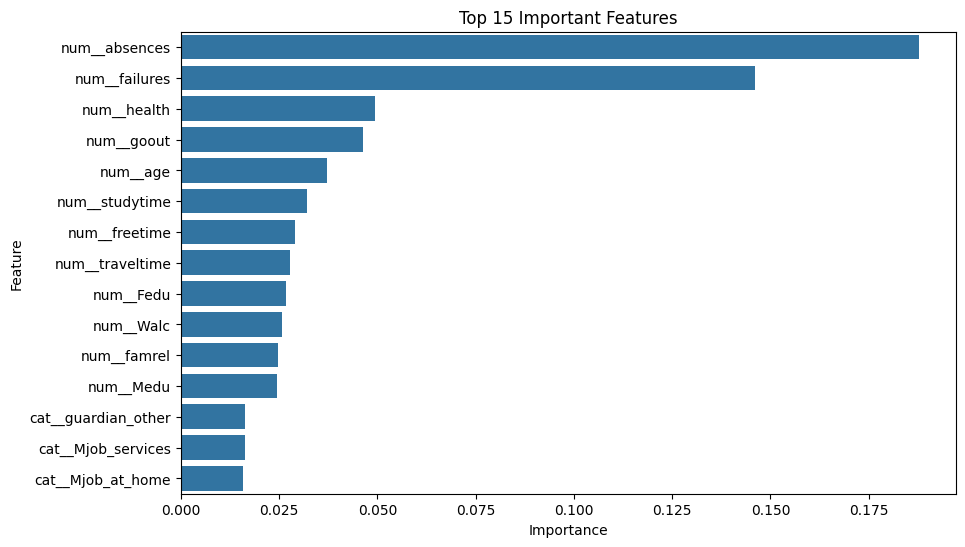

In [22]:
rf_pipeline = trained_models["Random Forest"]

rf_model = rf_pipeline.named_steps["model"]

feature_names = rf_pipeline.named_steps["preprocessing"].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15))

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")

plt.show()

In [23]:
new_student = pd.DataFrame([{
    "school": "GP",
    "sex": "F",
    "age": 17,
    "address": "U",
    "famsize": "GT3",
    "Pstatus": "T",
    "Medu": 4,
    "Fedu": 3,
    "Mjob": "teacher",
    "Fjob": "other",
    "reason": "course",
    "guardian": "mother",
    "traveltime": 1,
    "studytime": 3,
    "failures": 0,
    "schoolsup": "no",
    "famsup": "yes",
    "paid": "no",
    "activities": "yes",
    "nursery": "yes",
    "higher": "yes",
    "internet": "yes",
    "romantic": "no",
    "famrel": 4,
    "freetime": 3,
    "goout": 2,
    "Dalc": 1,
    "Walc": 1,
    "health": 5,
    "absences": 2
}])

predicted_grade = best_model.predict(new_student)[0]

print("Predicted Final Grade:", round(predicted_grade, 2))

Predicted Final Grade: 12.01


In [24]:
if predicted_grade < 10:
    risk_status = "High Academic Risk"
elif predicted_grade <= 12:
    risk_status = "Needs Monitoring"
else:
    risk_status = "Low Risk Flag"

print("Predicted Grade:", round(predicted_grade, 2))
print("Student Category:", risk_status)

Predicted Grade: 12.01
Student Category: Low Risk Flag


In [25]:
import joblib

joblib.dump(best_model, "student_marks_prediction_model.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [26]:
from google.colab import files

files.download("student_marks_prediction_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>